# Bird call data
1. Collect, check and filter the raw DOC / xeno-canto audio
2. Convert the clean recordings into model-ready log-mel spectrograms + MFCC

In [8]:
import sys, subprocess,json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, soundfile as sf
from IPython.display import Audio, display

DATA_ROOT = Path('.')   # folder holding DOC_001_Tier1, DOC_002_DuncanBayParinga, DOC_003_XenoCanto
OUT = Path('output')
LIMIT = None             # 300 for a quick trial run on a few clips per source
MAX_PER_CLASS = 500      # cap recordings per species for the spectrograms (0 = no cap)

def run(*args):
    # run a pipeline script with this notebook's Python and stream its output
    subprocess.run([sys.executable, *map(str, args)], check=True)

# 1. Collect,check, filter
Every clip is opened and checked for: unreadable, non-bird or ambiguous label, too short (< 1 s), silent, clipped, duplicate audio, and species with fewer than 10 clean clips. The train/val/test split is assigned per recording, so clips cut from one recording never leak between train and test.

Skipped automatically if `output/manifest_clean.csv` already exists; delete it to re-run

In [9]:
if not (OUT / 'manifest_clean.csv').exists():
    run('prepare_dataset.py', '--data-root', DATA_ROOT, '--out', OUT, *(['--limit', LIMIT] if LIMIT else []))

all_clips = pd.read_csv(OUT / 'manifest_all.csv', low_memory=False)
clean = pd.read_csv(OUT / 'manifest_clean.csv', low_memory=False)
print(f'{len(all_clips):,} clips checked -> {len(clean):,} kept ({len(clean)/len(all_clips):.1%}), '
      f'{clean.primary_label.nunique()} species')
all_clips.drop_reason.fillna('(kept)').value_counts().to_frame('clips')

271,365 clips checked -> 264,181 kept (97.4%), 88 species


,clips
drop_reason,
(kept),264181
non_bird_label,4218
ambiguous_label,2588
too_few_clips,157
clipped,122
duplicate_audio,98
unreadable,1


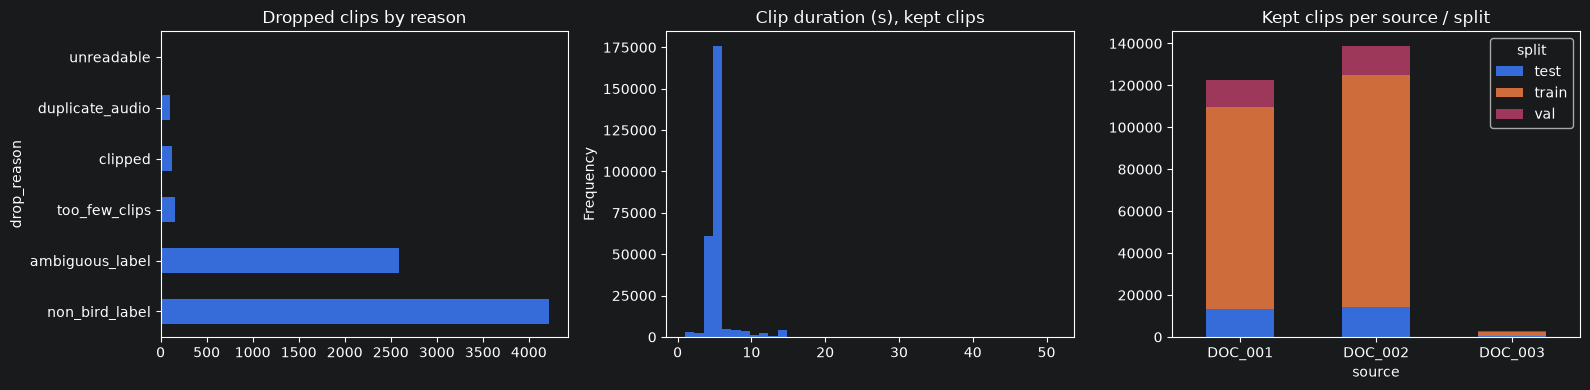

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
all_clips.drop_reason.dropna().value_counts().plot.barh(ax=ax[0], title='Dropped clips by reason')
clean.duration.plot.hist(bins=40, ax=ax[1], title='Clip duration (s), kept clips')
clean.groupby(['source', 'split']).size().unstack().plot.bar(stacked=True, ax=ax[2], title='Kept clips per source / split', rot=0)
ax[2].set_xticklabels([t.get_text()[:7] for t in ax[2].get_xticklabels()])
plt.tight_layout()

### Class balance
The imbalance is why `MAX_PER_CLASS` exists and why macro F1 (not accuracy) should be used later.

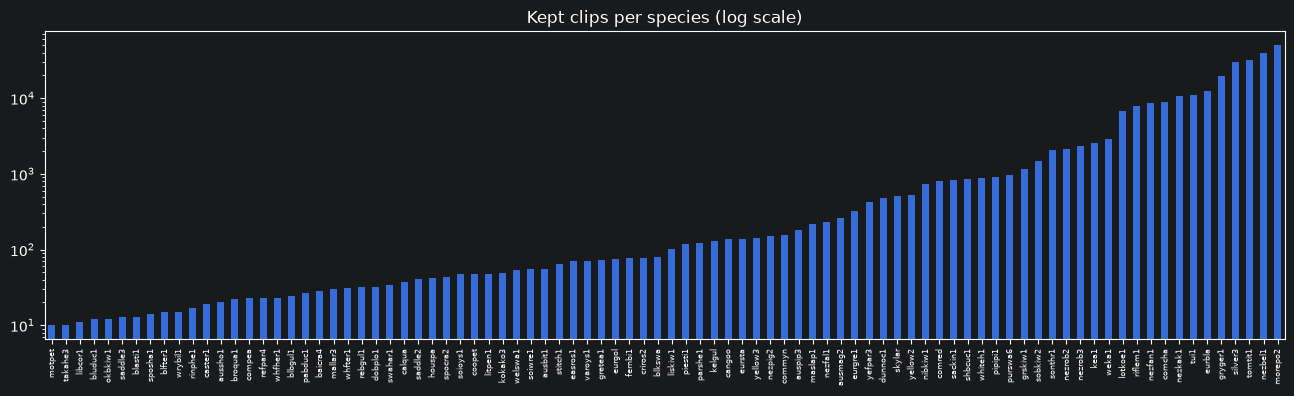

,,fewest clips
primary_label,common_name,
motpet,Mottled Petrel,10
takahe3,Takahe,10
libcor1,Little Black Shag,11
bluduc1,Blue Whio,12
okbkiw1,Okarito Brown Kiwi,12
saddle3,South Island Saddleback,13
blasti1,Black Stilt,13
sposha1,Spotted Shag,14
blfter1,Black-fronted Tern,15


,,most clips
primary_label,common_name,
gryger1,Grey Warbler,19661
silver3,Silvereye,30110
tomtit1,Tomtit,32392
nezbel1,Bellbird,39218
morepo2,Morepork,50004


In [11]:
per_species = clean.groupby(['primary_label', 'common_name'], dropna=False).size().sort_values()
fig, ax = plt.subplots(figsize=(16, 4))
per_species.plot.bar(ax=ax, logy=True, title='Kept clips per species (log scale)', xlabel='')
ax.set_xticklabels([l for l, _ in per_species.index], fontsize=6)
plt.show()
display(per_species.head(10).to_frame('fewest clips'), per_species.tail(5).to_frame('most clips'))

### Check few recording

In [12]:
for _, r in clean.sample(3, random_state=1).iterrows():
    print(r.primary_label, r.common_name, f'{r.duration:.1f}s', r.source)
    y, sr = sf.read(r.path)
    display(Audio(y, rate=sr))

nezbel1 Bellbird 5.0s DOC_001_Tier1


tomtit1 Tomtit 5.0s DOC_002_DuncanBayParinga


kea1 Kea 4.0s DOC_002_DuncanBayParinga


### Summary


In [13]:
print((OUT / 'qc_report.txt').read_text(encoding='utf-8').split('kept clips per species')[0])

total clips: 271365
kept clips: 264181 (97.4%)
kept species: 88

dropped by reason:
drop_reason
(kept)             264181
non_bird_label       4218
ambiguous_label      2588
too_few_clips         157
clipped               122
duplicate_audio        98
unreadable              1

kept clips per source:
source
DOC_002_DuncanBayParinga    138803
DOC_001_Tier1               122641
DOC_003_XenoCanto             2737

split (clips):
split
train    208543
test      28270
val       27368

sample rates seen:
sr
32000.0    271364

labels missing from bird_naming_map.csv:
badbird, barpar2, chaoys1, eurcoo, gragoo1, grwpet2, hutshe1, nezpig3, royalb2, sooshe, sopsku1, whcalb1

naming map rows sharing a scientific name (check these labels):
               CommonName   eBird         ScientificName ExtraName
                  Skylark brnsku3        Alauda arvensis   Skylark
                  Skylark  skylar        Alauda arvensis   Skylark
     South Island Fantail blafan1   Rhipidura fuliginosa   Fan

### 2. Spectrogram
- Each audio file is 32kHz and cut into 5-second clips, with at most 3 clips per file
- Each clip becomes a spectrogram, which is a picture of the sound. The vertical axis is pitch (128 bands) and the horizontal axis is time (313 frames)


In [14]:
if not (OUT / 'spectrogram_index.csv').exists():
    run('make_spectrograms.py', '--manifest', OUT / 'manifest_clean.csv', '--out', OUT, '--max-per-class', MAX_PER_CLASS)

idx = pd.read_csv(OUT / 'spectrogram_index.csv')
print(json.dumps(json.loads((OUT / 'spectrogram_config.json').read_text()), indent=1))
print(f'{len(idx):,} spectrograms, {idx.label.nunique()} species')
idx.groupby('split').agg(spectrograms=('spec_path', 'size'), species=('label', 'nunique'), recordings=('group', 'nunique'))

{
 "SR": 32000,
 "WINDOW_S": 5.0,
 "MIN_CHUNK_S": 2.0,
 "MAX_CHUNKS": 3,
 "N_FFT": 2048,
 "HOP": 512,
 "N_MELS": 128,
 "FMIN": 50,
 "FMAX": 15000,
 "N_MFCC": 20,
 "SEED": 42,
 "manifest": "output\\manifest_clean.csv",
 "max_per_class": 500,
 "frames": 313
}
24,145 spectrograms, 88 species


,spectrograms,species,recordings
split,,,
test,2869,88,1042
train,18765,88,8046
val,2511,88,1074


### Leak check : make sure no recording may appear in more than one split

In [15]:
assert idx.groupby('group').split.nunique().max() == 1, 'a recording appears in several splits!'
missing = set(idx.label) - set(idx[idx.split == 'test'].label)

### Example spectrograms

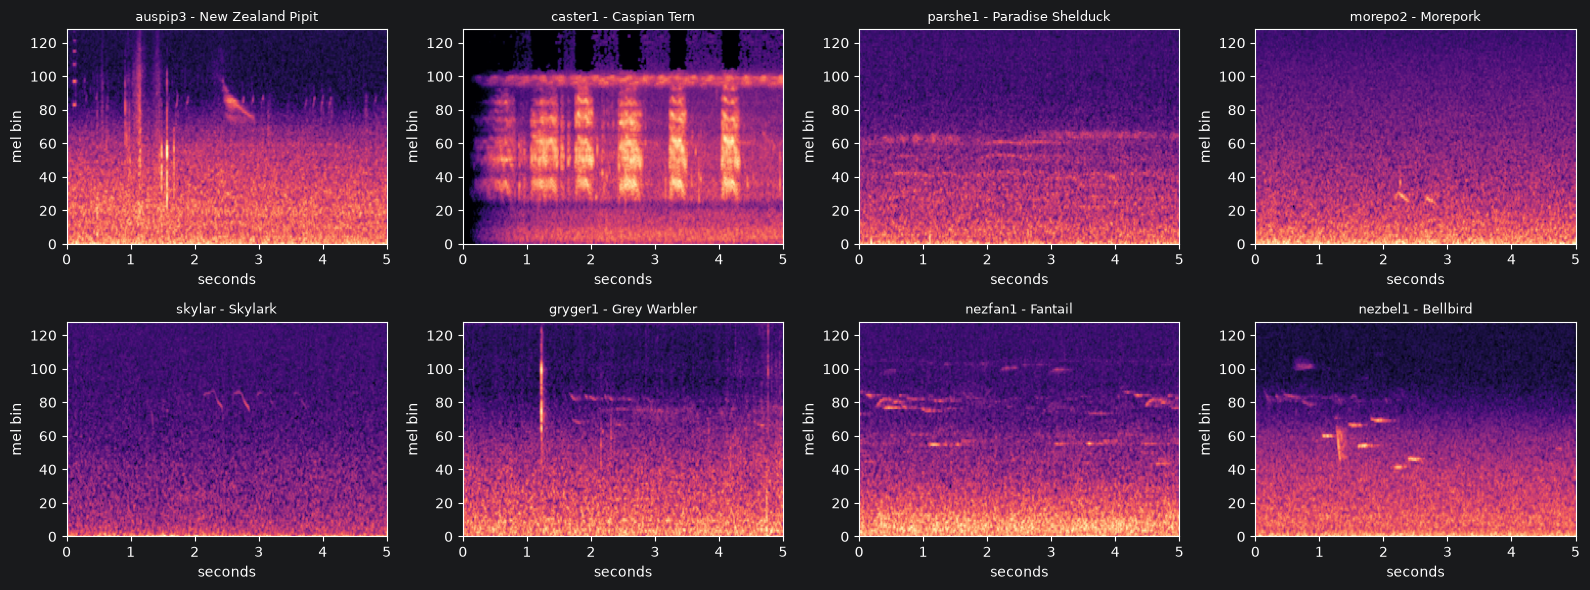

In [16]:
sample = idx.drop_duplicates('label').sample(8, random_state=0)
names = clean.drop_duplicates('primary_label').set_index('primary_label').common_name
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, (_, r) in zip(axes.flat, sample.iterrows()):
    s = np.load(OUT / r.spec_path).astype(np.float32)
    ax.imshow(s, origin='lower', aspect='auto', cmap='magma', extent=[0, 5, 0, s.shape[0]])
    ax.set_title(f'{r.label} - {names.get(r.label, "")}', fontsize=9)
    ax.set_xlabel('seconds'); ax.set_ylabel('mel bin')
plt.tight_layout()